In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [5]:
columns = [
    "engine_id",
    "cycle",
    "op_setting_1",
    "op_setting_2",
    "op_setting_3",
    "sensor_1",
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_5",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_10",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_16",
    "sensor_17",
    "sensor_18",
    "sensor_19",
    "sensor_20",
    "sensor_21"
]

In [6]:
train_path = "data/train_FD001.txt"

train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None,
    names=columns
)

train_df.head()

,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [7]:
train_df.shape

(20631, 26)

In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   engine_id     20631 non-null  int64  
 1   cycle         20631 non-null  int64  
 2   op_setting_1  20631 non-null  float64
 3   op_setting_2  20631 non-null  float64
 4   op_setting_3  20631 non-null  float64
 5   sensor_1      20631 non-null  float64
 6   sensor_2      20631 non-null  float64
 7   sensor_3      20631 non-null  float64
 8   sensor_4      20631 non-null  float64
 9   sensor_5      20631 non-null  float64
 10  sensor_6      20631 non-null  float64
 11  sensor_7      20631 non-null  float64
 12  sensor_8      20631 non-null  float64
 13  sensor_9      20631 non-null  float64
 14  sensor_10     20631 non-null  float64
 15  sensor_11     20631 non-null  float64
 16  sensor_12     20631 non-null  float64
 17  sensor_13     20631 non-null  float64
 18  sensor_14     20631 non-nu

In [9]:
train_df.describe()

,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


In [10]:
# Find columns with zero variance
constant_columns = [
    col for col in train_df.columns
    if train_df[col].nunique() <= 1
]

print("Constant columns:")
print(constant_columns)

Constant columns:
['op_setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


In [11]:
# Find columns with very low variance
numeric_cols = train_df.select_dtypes(include=np.number).columns

variance = train_df[numeric_cols].var()

low_variance = variance[variance < 0.01].sort_values()

print("Low variance columns:")
print(low_variance)

Low variance columns:
sensor_1        0.000000e+00
op_setting_3    0.000000e+00
sensor_10       0.000000e+00
sensor_18       0.000000e+00
sensor_19       0.000000e+00
sensor_16       1.203765e-35
sensor_5        2.840037e-29
op_setting_2    8.588541e-08
sensor_6        1.929279e-06
op_setting_1    4.784340e-06
sensor_15       1.406628e-03
sensor_8        5.038938e-03
sensor_13       5.172330e-03
dtype: float64


In [12]:
# Calculate the maximum cycle for each engine
max_cycle = train_df.groupby("engine_id")["cycle"].max()

# Map maximum cycle back to every row
train_df["max_cycle"] = train_df["engine_id"].map(max_cycle)

# Calculate RUL
train_df["RUL"] = train_df["max_cycle"] - train_df["cycle"]

train_df[["engine_id", "cycle", "max_cycle", "RUL"]].head(10)

,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


In [13]:
# Correlation of each numeric feature with cycle
correlation_with_cycle = (
    train_df.corr(numeric_only=True)["cycle"]
    .sort_values()
)

print(correlation_with_cycle)

RUL            -0.736241
sensor_12      -0.611354
sensor_7       -0.595914
sensor_21      -0.585923
sensor_20      -0.583597
op_setting_1   -0.004527
op_setting_2    0.016132
engine_id       0.078753
sensor_6        0.105980
max_cycle       0.363152
sensor_14       0.370324
sensor_9        0.443999
sensor_8        0.475977
sensor_13       0.477523
sensor_3        0.543947
sensor_2        0.549898
sensor_17       0.566995
sensor_15       0.588676
sensor_4        0.624577
sensor_11       0.634385
cycle           1.000000
op_setting_3         NaN
sensor_1             NaN
sensor_5             NaN
sensor_10            NaN
sensor_16            NaN
sensor_18            NaN
sensor_19            NaN
Name: cycle, dtype: float64


In [14]:
# Correlation of sensors with cycle
sensor_columns = [col for col in train_df.columns if col.startswith("sensor_")]

cycle_corr = train_df[sensor_columns].corrwith(train_df["cycle"]).sort_values()

print(cycle_corr)

sensor_12   -6.113536e-01
sensor_7    -5.959136e-01
sensor_21   -5.859234e-01
sensor_20   -5.835969e-01
sensor_16   -4.553716e-16
sensor_5     1.305633e-15
sensor_6     1.059800e-01
sensor_14    3.703236e-01
sensor_9     4.439993e-01
sensor_8     4.759773e-01
sensor_13    4.775230e-01
sensor_3     5.439470e-01
sensor_2     5.498980e-01
sensor_17    5.669949e-01
sensor_15    5.886758e-01
sensor_4     6.245772e-01
sensor_11    6.343845e-01
sensor_1              NaN
sensor_10             NaN
sensor_18             NaN
sensor_19             NaN
dtype: float64


C:\Users\rimjh\projects\agents\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3063: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\rimjh\projects\agents\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3064: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


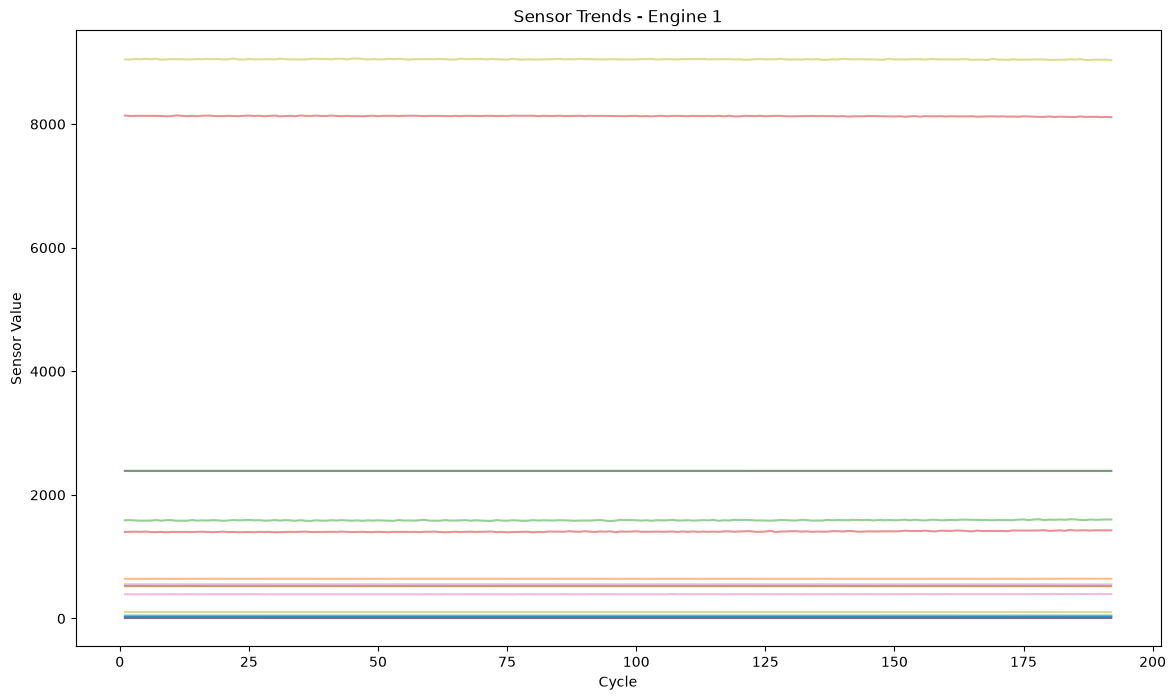

In [15]:
# Plot sensor trends for one engine
engine_1 = train_df[train_df["engine_id"] == 1]

plt.figure(figsize=(14, 8))

for sensor in sensor_columns:
    plt.plot(engine_1["cycle"], engine_1[sensor], alpha=0.5)

plt.xlabel("Cycle")
plt.ylabel("Sensor Value")
plt.title("Sensor Trends - Engine 1")
plt.show()

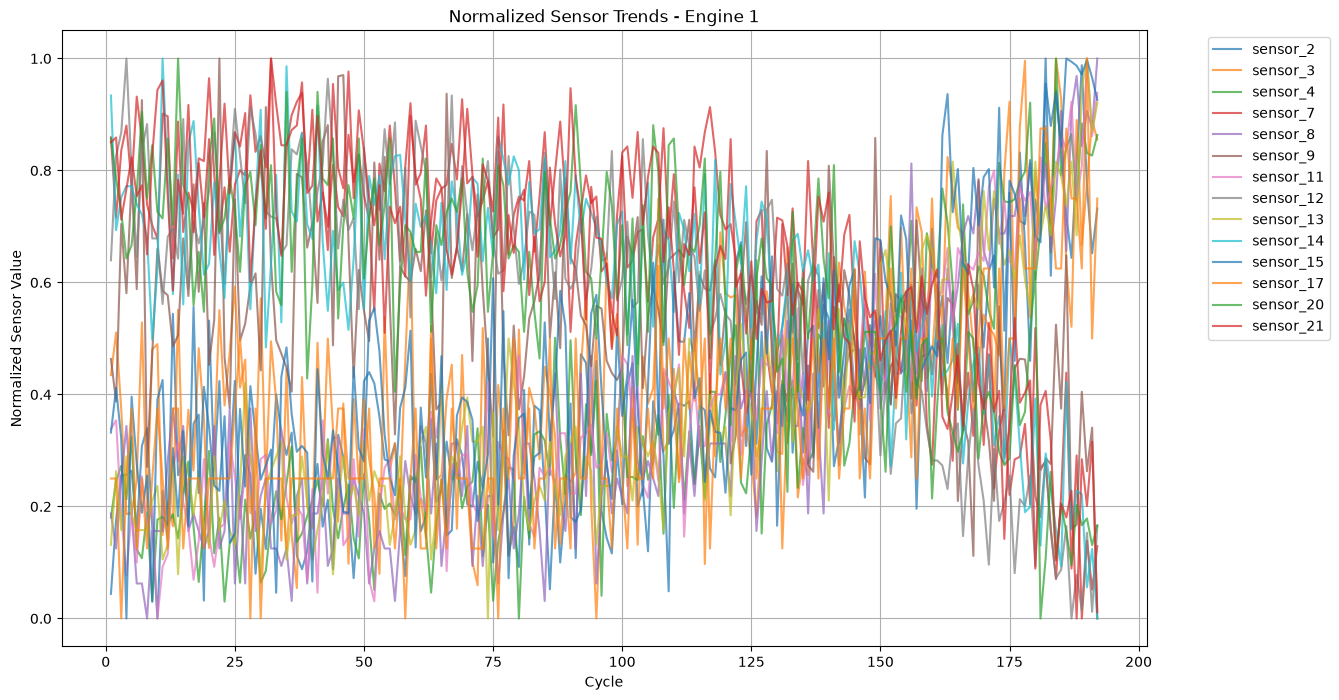

In [16]:
# Normalize sensors for visualization
engine_1 = train_df[train_df["engine_id"] == 1].copy()

plt.figure(figsize=(14, 8))

for sensor in sensor_columns:
    values = engine_1[sensor]

    # Skip constant sensors
    if values.nunique() <= 1:
        continue

    normalized = (values - values.min()) / (values.max() - values.min())

    plt.plot(
        engine_1["cycle"],
        normalized,
        label=sensor,
        alpha=0.7
    )

plt.xlabel("Cycle")
plt.ylabel("Normalized Sensor Value")
plt.title("Normalized Sensor Trends - Engine 1")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.show()

In [17]:
rul_corr = train_df[sensor_columns].corrwith(train_df["RUL"]).sort_values()

print(rul_corr)

sensor_11   -6.962281e-01
sensor_4    -6.789482e-01
sensor_15   -6.426670e-01
sensor_2    -6.064840e-01
sensor_17   -6.061536e-01
sensor_3    -5.845204e-01
sensor_8    -5.639684e-01
sensor_13   -5.625688e-01
sensor_9    -3.901016e-01
sensor_14   -3.067689e-01
sensor_6    -1.283484e-01
sensor_16   -5.849749e-16
sensor_5     1.251872e-15
sensor_20    6.294285e-01
sensor_21    6.356620e-01
sensor_7     6.572227e-01
sensor_12    6.719831e-01
sensor_1              NaN
sensor_10             NaN
sensor_18             NaN
sensor_19             NaN
dtype: float64


C:\Users\rimjh\projects\agents\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3063: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\rimjh\projects\agents\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3064: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [18]:
# Remove constant sensors first
useful_sensors = [
    col for col in sensor_columns
    if train_df[col].nunique() > 1
]

# Correlation with RUL
rul_corr = (
    train_df[useful_sensors]
    .corrwith(train_df["RUL"])
    .sort_values(key=abs, ascending=False)
)

print("Sensors ranked by absolute correlation with RUL:")
print(rul_corr)

Sensors ranked by absolute correlation with RUL:
sensor_11   -0.696228
sensor_4    -0.678948
sensor_12    0.671983
sensor_7     0.657223
sensor_15   -0.642667
sensor_21    0.635662
sensor_20    0.629428
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
dtype: float64


In [19]:
useful_sensors = [
    col for col in sensor_columns
    if train_df[col].nunique() > 1
]

rul_corr = (
    train_df[useful_sensors]
    .corrwith(train_df["RUL"])
    .sort_values(key=abs, ascending=False)
)

print(rul_corr)

sensor_11   -0.696228
sensor_4    -0.678948
sensor_12    0.671983
sensor_7     0.657223
sensor_15   -0.642667
sensor_21    0.635662
sensor_20    0.629428
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
dtype: float64


In [20]:
selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

In [21]:
constant_columns = [
    "op_setting_3",
    "sensor_1",
    "sensor_5",
    "sensor_10",
    "sensor_16",
    "sensor_18",
    "sensor_19"
]

In [22]:
# Check sensor correlation with RUL by individual engine

for sensor in selected_sensors:
    correlations = (
        train_df.groupby("engine_id")
        .apply(lambda x: x[sensor].corr(x["RUL"]), include_groups=False)
    )

    print(f"\n{sensor}")
    print("Mean correlation:", correlations.mean())
    print("Std correlation :", correlations.std())


sensor_2
Mean correlation: -0.6752756106641428
Std correlation : 0.059758074589804464

sensor_3
Mean correlation: -0.6439503481802928
Std correlation : 0.057739245438581194

sensor_4
Mean correlation: -0.7816136711112748
Std correlation : 0.038111974332322544

sensor_7
Mean correlation: 0.7615143940109727
Std correlation : 0.059693604003649474

sensor_8
Mean correlation: -0.683526241131408
Std correlation : 0.19314855437372802

sensor_9
Mean correlation: -0.38595548514739414
Std correlation : 0.5700835392353032

sensor_11
Mean correlation: -0.8106012169818558
Std correlation : 0.039929387515441436

sensor_12
Mean correlation: 0.78966224936546
Std correlation : 0.05294220616296601

sensor_13
Mean correlation: -0.6873161247995505
Std correlation : 0.1901904969165648

sensor_14
Mean correlation: -0.2235038612172007
Std correlation : 0.6887773587373626

sensor_15
Mean correlation: -0.7248441832436676
Std correlation : 0.04973514040749748

sensor_17
Mean correlation: -0.6731228647815104
St

In [23]:
selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

In [24]:
train_df = train_df.sort_values(["engine_id", "cycle"])

In [25]:
# Keep the dataframe ordered chronologically for each engine
train_df = train_df.sort_values(["engine_id", "cycle"]).reset_index(drop=True)

print(train_df[["engine_id", "cycle", "RUL"]].head(10))

   engine_id  cycle  RUL
0          1      1  191
1          1      2  190
2          1      3  189
3          1      4  188
4          1      5  187
5          1      6  186
6          1      7  185
7          1      8  184
8          1      9  183
9          1     10  182


In [26]:
# Sensors selected based on our EDA
selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

# Create temporal features separately for each engine
for sensor in selected_sensors:
    
    # Change from previous cycle
    train_df[f"{sensor}_delta"] = (
        train_df.groupby("engine_id")[sensor].diff()
    )
    
    # Rolling average over previous 5 cycles
    train_df[f"{sensor}_roll_mean_5"] = (
        train_df.groupby("engine_id")[sensor]
        .transform(lambda x: x.rolling(window=5, min_periods=1).mean())
    )
    
    # Rolling average over previous 10 cycles
    train_df[f"{sensor}_roll_mean_10"] = (
        train_df.groupby("engine_id")[sensor]
        .transform(lambda x: x.rolling(window=10, min_periods=1).mean())
    )
    
    # Rolling standard deviation over 10 cycles
    train_df[f"{sensor}_roll_std_10"] = (
        train_df.groupby("engine_id")[sensor]
        .transform(lambda x: x.rolling(window=10, min_periods=1).std())
    )

print("Feature engineering completed!")
print("New shape:", train_df.shape)

Feature engineering completed!
New shape: (20631, 68)


In [27]:
# Check missing values after feature engineering

missing = train_df.isnull().sum()

print("Columns with missing values:")
print(missing[missing > 0])

print("\nTotal missing values:", train_df.isnull().sum().sum())

Columns with missing values:
sensor_2_delta           100
sensor_2_roll_std_10     100
sensor_3_delta           100
sensor_3_roll_std_10     100
sensor_4_delta           100
sensor_4_roll_std_10     100
sensor_7_delta           100
sensor_7_roll_std_10     100
sensor_11_delta          100
sensor_11_roll_std_10    100
sensor_12_delta          100
sensor_12_roll_std_10    100
sensor_15_delta          100
sensor_15_roll_std_10    100
sensor_17_delta          100
sensor_17_roll_std_10    100
sensor_20_delta          100
sensor_20_roll_std_10    100
sensor_21_delta          100
sensor_21_roll_std_10    100
dtype: int64

Total missing values: 2000


In [28]:
# Inspect engineered features for Engine 1

check_columns = [
    "engine_id",
    "cycle",
    "sensor_11",
    "sensor_11_delta",
    "sensor_11_roll_mean_5",
    "sensor_11_roll_mean_10",
    "sensor_11_roll_std_10",
    "RUL"
]

print(train_df[check_columns].head(15))

    engine_id  cycle  sensor_11  sensor_11_delta  sensor_11_roll_mean_5  \
0           1      1      47.47              NaN                 47.470   
1           1      2      47.49             0.02                 47.480   
2           1      3      47.27            -0.22                 47.410   
3           1      4      47.13            -0.14                 47.340   
4           1      5      47.28             0.15                 47.328   
5           1      6      47.16            -0.12                 47.266   
6           1      7      47.36             0.20                 47.240   
7           1      8      47.24            -0.12                 47.234   
8           1      9      47.29             0.05                 47.266   
9           1     10      47.03            -0.26                 47.216   
10          1     11      47.15             0.12                 47.214   
11          1     12      47.18             0.03                 47.178   
12          1     13     

In [29]:
# Fill NaN values created by temporal features

for sensor in selected_sensors:
    train_df[f"{sensor}_delta"] = (
        train_df[f"{sensor}_delta"].fillna(0)
    )
    
    train_df[f"{sensor}_roll_std_10"] = (
        train_df[f"{sensor}_roll_std_10"].fillna(0)
    )

print("Total missing values:", train_df.isnull().sum().sum())

Total missing values: 0


In [30]:
from sklearn.model_selection import train_test_split

# Get unique engine IDs
engine_ids = train_df["engine_id"].unique()

# Split engines, not individual rows
train_engines, val_engines = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))
# %pip install scikit-learn

Training engines: 80
Validation engines: 20


In [31]:
train_data = train_df[
    train_df["engine_id"].isin(train_engines)
].copy()

val_data = train_df[
    train_df["engine_id"].isin(val_engines)
].copy()

print("Train shape:", train_data.shape)
print("Validation shape:", val_data.shape)

Train shape: (16561, 68)
Validation shape: (4070, 68)


In [32]:
drop_columns = ["engine_id", "RUL", "max_cycle"]

feature_columns = [
    col for col in train_data.columns
    if col not in drop_columns
]

X_train = train_data[feature_columns]
y_train = train_data["RUL"]

X_val = val_data[feature_columns]
y_val = val_data["RUL"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (16561, 65)
y_train: (16561,)
X_val: (4070, 65)
y_val: (4070,)


In [33]:

%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\rimjh\projects\agents\.venv\Scripts\python.exe -m pip install --upgrade pip


In [34]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [35]:
model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [36]:
import xgboost as xgb

model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("Model training completed!")

Model training completed!


In [37]:
y_pred = model.predict(X_val)

print("Predictions generated!")
print("First 10 predictions:")
print(y_pred[:10])

Predictions generated!
First 10 predictions:
[235.3305  226.02974 211.06947 229.74254 249.35234 240.6695  215.55118
 200.8529  202.2722  190.10738]


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print("Model Performance")
print("------------------")
print("MAE  :", mae)
print("RMSE :", rmse)
print("R²   :", r2)

Model Performance
------------------
MAE  : 23.494821548461914
RMSE : 31.13534533297979
R²   : 0.7750879526138306


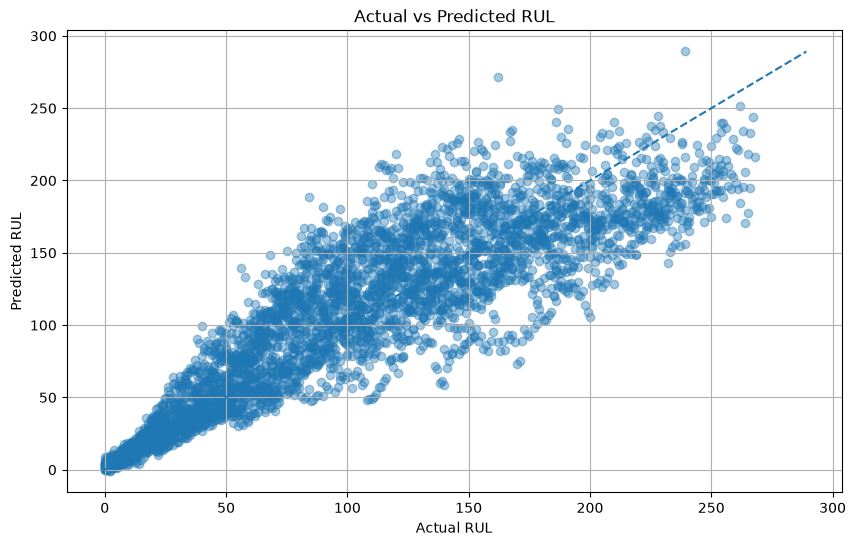

In [39]:
plt.figure(figsize=(10, 6))

plt.scatter(y_val, y_pred, alpha=0.4)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")

# Perfect prediction line
min_rul = min(y_val.min(), y_pred.min())
max_rul = max(y_val.max(), y_pred.max())

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.grid(True)
plt.show()

In [40]:
# Feature importance from XGBoost

importance = (
    pd.Series(model.feature_importances_, index=X_train.columns)
    .sort_values(ascending=False)
)

print("Top 20 important features:")
print(importance.head(20))

Top 20 important features:
cycle                     0.176125
sensor_4_roll_mean_5      0.090611
sensor_11_roll_mean_5     0.087592
sensor_15_roll_mean_10    0.074826
sensor_4_roll_mean_10     0.045754
sensor_3_roll_mean_10     0.044602
sensor_2_roll_mean_10     0.032994
sensor_15_roll_mean_5     0.030009
sensor_9                  0.024902
sensor_21_roll_mean_10    0.023047
sensor_21_roll_mean_5     0.020956
sensor_14                 0.018600
sensor_12_roll_mean_10    0.017456
sensor_7_roll_mean_10     0.017257
sensor_11_roll_mean_10    0.016412
sensor_17_roll_mean_10    0.014363
sensor_12_roll_mean_5     0.013998
sensor_15_roll_std_10     0.012881
sensor_20_roll_mean_10    0.012877
sensor_12_roll_std_10     0.011772
dtype: float32


 plt.figure(figsize=(10, 8))

importance.head(20).sort_values().plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Features")

plt.show()

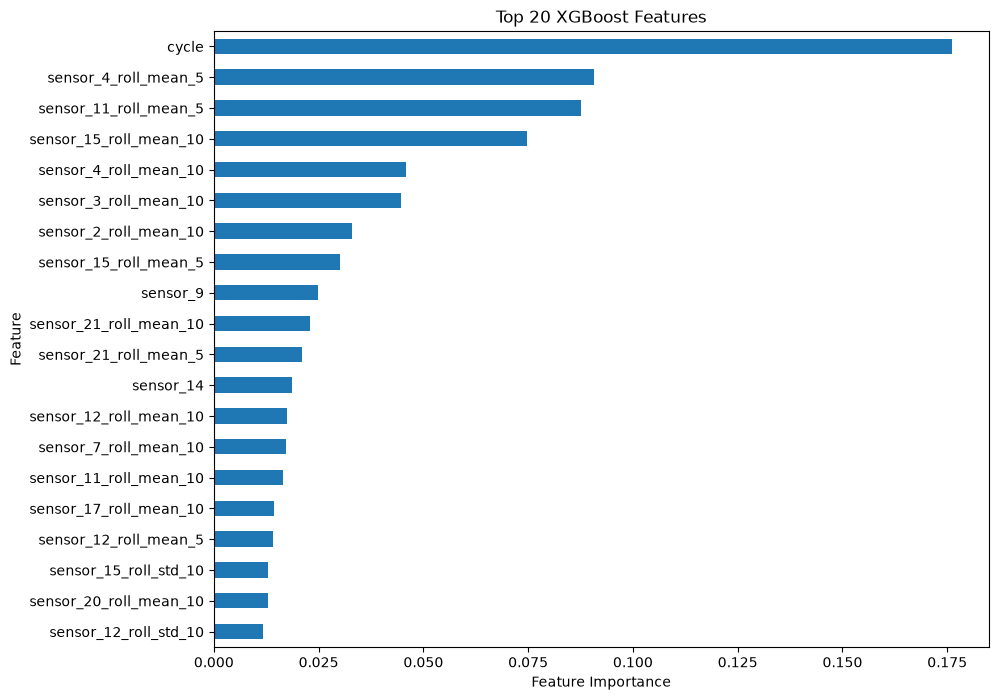

In [41]:
plt.figure(figsize=(10, 8))

importance.head(20).sort_values().plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Features")

plt.show()

In [42]:
# Raw features only
raw_drop_columns = [
    "engine_id",
    "RUL",
    "max_cycle"
]

raw_feature_columns = [
    col for col in train_data.columns
    if col not in raw_drop_columns
    and "_delta" not in col
    and "_roll_mean_" not in col
    and "_roll_std_" not in col
]

X_train_raw = train_data[raw_feature_columns]
X_val_raw = val_data[raw_feature_columns]

print("Raw features:", len(raw_feature_columns))
print("X_train_raw:", X_train_raw.shape)
print("X_val_raw:", X_val_raw.shape)

Raw features: 25
X_train_raw: (16561, 25)
X_val_raw: (4070, 25)


In [43]:
raw_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

raw_model.fit(
    X_train_raw,
    y_train,
    eval_set=[(X_val_raw, y_val)],
    verbose=False
)

raw_pred = raw_model.predict(X_val_raw)

raw_mae = mean_absolute_error(y_val, raw_pred)
raw_rmse = np.sqrt(mean_squared_error(y_val, raw_pred))
raw_r2 = r2_score(y_val, raw_pred)

print("Raw Model Performance")
print("---------------------")
print("MAE  :", raw_mae)
print("RMSE :", raw_rmse)
print("R²   :", raw_r2)

Raw Model Performance
---------------------
MAE  : 23.960411071777344
RMSE : 31.690290881164415
R²   : 0.7669990062713623


In [44]:
models = {
    "Model_1": xgb.XGBRegressor(
        n_estimators=800,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    ),

    "Model_2": xgb.XGBRegressor(
        n_estimators=600,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=42
    ),

    "Model_3": xgb.XGBRegressor(
        n_estimators=700,
        learning_rate=0.03,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )
}

results = []

for name, m in models.items():

    m.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    pred = m.predict(X_val)

    mae = mean_absolute_error(y_val, pred)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    r2 = r2_score(y_val, pred)

    results.append([name, mae, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "RMSE", "R2"]
)

print(results_df)

     Model        MAE       RMSE        R2
0  Model_1  23.497482  31.006242  0.776949
1  Model_2  23.575750  30.965746  0.777532
2  Model_3  23.492043  31.132745  0.775126


In [45]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\rimjh\Documents\Study\aircraft_predictive_maintenance
['.ipynb_checkpoints', '.vscode', 'Aircraft_RUL_Software', 'app.py', 'cmapss_eda.ipynb', 'data', 'final_rul_predictions.csv', 'inputs', 'model', 'test_FD001.txt', 'xgboost_rul_final.pkl']


In [46]:
print(os.listdir("data"))

['.ipynb_checkpoints', 'Damage Propagation Modeling.pdf', 'readme.txt', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']


In [47]:
test_df = pd.read_csv(
    "data/test_FD001.txt",
    sep=r"\s+",
    header=None
)

rul_test = pd.read_csv(
    "data/RUL_FD001.txt",
    header=None
)

print("Test shape:", test_df.shape)
print("RUL shape:", rul_test.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'data/test_FD001.txt'

In [48]:
# Load test data
test_df = pd.read_csv(
    "data/test_FD001.txt",
    sep=r"\s+",
    header=None
)

# Load true RUL values for test engines
rul_test = pd.read_csv(
    "data/RUL_FD001.txt",
    header=None
)

# Same column names as training data
columns = [
    "engine_id",
    "cycle",
    "op_setting_1",
    "op_setting_2",
    "op_setting_3",
] + [f"sensor_{i}" for i in range(1, 22)]

test_df.columns = columns
rul_test.columns = ["RUL"]

print("Test shape:", test_df.shape)
print("RUL shape:", rul_test.shape)

print("\nTest data:")
print(test_df.head())

print("\nTest RUL:")
print(rul_test.head())

FileNotFoundError: [Errno 2] No such file or directory: 'data/test_FD001.txt'

In [49]:
# Calculate RUL for every test row

test_df = test_df.sort_values(
    ["engine_id", "cycle"]
).reset_index(drop=True)

# Maximum observed cycle for each test engine
max_test_cycle = test_df.groupby("engine_id")["cycle"].transform("max")

# RUL given in RUL_FD001.txt corresponds to the last observed cycle
test_df["RUL"] = (
    max_test_cycle
    - test_df["cycle"]
    + rul_test.loc[test_df["engine_id"] - 1, "RUL"].values
)

print(test_df[["engine_id", "cycle", "RUL"]].head(10))

NameError: name 'test_df' is not defined

In [ ]:
# Verify final cycle RUL against RUL_FD001

last_test_rows = (
    test_df
    .sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
)

comparison = pd.DataFrame({
    "engine_id": last_test_rows["engine_id"].values,
    "calculated_RUL": last_test_rows["RUL"].values,
    "provided_RUL": rul_test["RUL"].values
})

print(comparison.head(10))
print("\nAll values match:",
      (comparison["calculated_RUL"] == comparison["provided_RUL"]).all())

In [50]:
print(X_train.columns.tolist())

['cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'sensor_2_delta', 'sensor_2_roll_mean_5', 'sensor_2_roll_mean_10', 'sensor_2_roll_std_10', 'sensor_3_delta', 'sensor_3_roll_mean_5', 'sensor_3_roll_mean_10', 'sensor_3_roll_std_10', 'sensor_4_delta', 'sensor_4_roll_mean_5', 'sensor_4_roll_mean_10', 'sensor_4_roll_std_10', 'sensor_7_delta', 'sensor_7_roll_mean_5', 'sensor_7_roll_mean_10', 'sensor_7_roll_std_10', 'sensor_11_delta', 'sensor_11_roll_mean_5', 'sensor_11_roll_mean_10', 'sensor_11_roll_std_10', 'sensor_12_delta', 'sensor_12_roll_mean_5', 'sensor_12_roll_mean_10', 'sensor_12_roll_std_10', 'sensor_15_delta', 'sensor_15_roll_mean_5', 'sensor_15_roll_mean_10', 'sensor_15_roll_std_10', 'sensor_17_delta', 'sensor_17

In [51]:
# ============================================================
# Create the exact same engineered features for TEST data
# ============================================================

test_engineered = test_df.copy()

selected_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

# Sort first so rolling/delta calculations happen
# correctly within each engine
test_engineered = test_engineered.sort_values(
    ["engine_id", "cycle"]
).reset_index(drop=True)

for sensor in selected_sensors:

    # Change from previous cycle
    test_engineered[f"{sensor}_delta"] = (
        test_engineered.groupby("engine_id")[sensor]
        .diff()
    )

    # Rolling mean - last 5 observations
    test_engineered[f"{sensor}_roll_mean_5"] = (
        test_engineered.groupby("engine_id")[sensor]
        .transform(lambda x: x.rolling(5, min_periods=1).mean())
    )

    # Rolling mean - last 10 observations
    test_engineered[f"{sensor}_roll_mean_10"] = (
        test_engineered.groupby("engine_id")[sensor]
        .transform(lambda x: x.rolling(10, min_periods=1).mean())
    )

    # Rolling standard deviation - last 10 observations
    test_engineered[f"{sensor}_roll_std_10"] = (
        test_engineered.groupby("engine_id")[sensor]
        .transform(lambda x: x.rolling(10, min_periods=1).std())
    )

print("Test feature engineering completed!")
print("Shape:", test_engineered.shape)

NameError: name 'test_df' is not defined

In [52]:
# Handle missing values exactly before prediction

test_engineered = test_engineered.fillna(0)

print("Total missing values:",
      test_engineered.isnull().sum().sum())

NameError: name 'test_engineered' is not defined

In [53]:
test_features = test_engineered[X_train.columns]

print("Test features shape:", test_features.shape)
print("Training features shape:", X_train.shape)

print("\nSame columns:",
      list(test_features.columns) == list(X_train.columns))

NameError: name 'test_engineered' is not defined

In [ ]:
# Use the tuned Model 2 for test prediction

final_model = models["Model_2"]

# Predict RUL on completely unseen test engines
test_pred = final_model.predict(test_features)

print("Test predictions generated!")
print(test_pred[:10])

In [ ]:
test_mae = mean_absolute_error(test_df["RUL"], test_pred)
test_rmse = np.sqrt(mean_squared_error(test_df["RUL"], test_pred))
test_r2 = r2_score(test_df["RUL"], test_pred)

print("\nFINAL TEST PERFORMANCE")
print("----------------------")
print("MAE  :", test_mae)
print("RMSE :", test_rmse)
print("R²   :", test_r2)

In [54]:
# Last observed cycle of every test engine
last_test_rows = (
    test_engineered
    .sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
)

# Features for the 100 final observations
X_test_final = last_test_rows[X_train.columns]

# Actual RUL from RUL_FD001
y_test_final = last_test_rows["RUL"]

# Predict
final_pred = final_model.predict(X_test_final)

# Metrics
final_mae = mean_absolute_error(y_test_final, final_pred)
final_rmse = np.sqrt(mean_squared_error(y_test_final, final_pred))
final_r2 = r2_score(y_test_final, final_pred)

print("FINAL TEST-POINT PERFORMANCE")
print("----------------------------")
print("MAE  :", final_mae)
print("RMSE :", final_rmse)
print("R²   :", final_r2)

NameError: name 'test_engineered' is not defined

In [55]:
comparison = pd.DataFrame({
    "engine_id": last_test_rows["engine_id"].values,
    "actual_RUL": y_test_final.values,
    "predicted_RUL": final_pred
})

comparison["error"] = (
    comparison["predicted_RUL"] - comparison["actual_RUL"]
)

print(comparison.head(20))

NameError: name 'last_test_rows' is not defined

In [ ]:
# Error analysis

comparison["abs_error"] = comparison["error"].abs()

print("Worst 15 predictions:")
print(
    comparison
    .sort_values("abs_error", ascending=False)
    .head(15)
)

In [56]:

print("\nError statistics:")
print(comparison["error"].describe())


Error statistics:


NameError: name 'comparison' is not defined

In [57]:
plt.figure(figsize=(10, 6))

plt.scatter(
    comparison["actual_RUL"],
    comparison["predicted_RUL"],
    alpha=0.7
)

min_rul = min(comparison["actual_RUL"].min(),
              comparison["predicted_RUL"].min())

max_rul = max(comparison["actual_RUL"].max(),
              comparison["predicted_RUL"].max())

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Final Test-Point: Actual vs Predicted RUL")
plt.grid(True)
plt.show()

NameError: name 'comparison' is not defined

<Figure size 1000x600 with 0 Axes>

In [ ]:
print(train_df.columns.tolist())

In [ ]:
print(X_train.columns.tolist()[-10:])

In [ ]:
# Add normalized life progress

train_df["life_progress"] = (
    train_df["cycle"] / train_df["max_cycle"]
)

test_engineered["life_progress"] = (
    test_engineered["cycle"] /
    test_engineered.groupby("engine_id")["cycle"].transform("max")
)

print(train_df[[
    "engine_id",
    "cycle",
    "max_cycle",
    "life_progress",
    "RUL"
]].head(10))

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    comparison["actual_RUL"],
    comparison["predicted_RUL"],
    alpha=0.7
)

min_rul = min(
    comparison["actual_RUL"].min(),
    comparison["predicted_RUL"].min()
)

max_rul = max(
    comparison["actual_RUL"].max(),
    comparison["predicted_RUL"].max()
)

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Final Test")
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(comparison["error"], bins=20)

plt.axvline(0, linestyle="--")

plt.xlabel("Prediction Error")
plt.ylabel("Number of Engines")
plt.title("RUL Prediction Error Distribution")
plt.grid(True)
plt.show()

In [ ]:
worst_predictions = (
    comparison
    .sort_values("abs_error", ascending=False)
    .head(10)
)

print(worst_predictions)

In [ ]:
import joblib

joblib.dump(model, "xgboost_rul_final.pkl")

print("Final model saved successfully!")

In [ ]:
print("=" * 45)
print("FINAL RUL MODEL RESULTS")
print("=" * 45)

print(f"Validation MAE  : {23.575750:.2f}")
print(f"Validation RMSE : {30.965746:.2f}")
print(f"Validation R²   : {0.777532:.3f}")

print()

print(f"Test MAE        : {19.714009:.2f}")
print(f"Test RMSE       : {27.675763:.2f}")
print(f"Test R²         : {0.556453:.3f}")

print("=" * 45)

In [ ]:
import joblib

# Save trained model
joblib.dump(model, "final_rul_xgboost_model.pkl")

print("Model saved successfully!")

In [ ]:
feature_names = X_train.columns.tolist()

joblib.dump(feature_names, "rul_feature_names.pkl")

print("Feature names saved!")
print("Number of features:", len(feature_names))

In [ ]:
final_results = {
    "Validation MAE": 23.58,
    "Validation RMSE": 30.97,
    "Validation R2": 0.778,
    "Test MAE": 19.71,
    "Test RMSE": 27.68,
    "Test R2": 0.556
}

print("FINAL RUL MODEL RESULTS")
print("========================")

for key, value in final_results.items():
    print(f"{key}: {value}")

In [ ]:
comparison.to_csv("final_rul_predictions.csv", index=False)

print("Prediction results saved!")
print("Rows:", len(comparison))

In [58]:
import os

files = [
    "final_rul_xgboost_model.pkl",
    "rul_feature_names.pkl",
    "final_rul_predictions.csv"
]

for file in files:
    print(file, "->", "EXISTS" if os.path.exists(file) else "MISSING")

final_rul_xgboost_model.pkl -> MISSING
rul_feature_names.pkl -> MISSING
final_rul_predictions.csv -> EXISTS


In [59]:
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (16561, 65)


NameError: name 'X_test' is not defined

In [60]:
# Check which train/test variables currently exist
print([var for var in dir() if "train" in var.lower() or "test" in var.lower()])

['X_train', 'X_train_raw', 'train_data', 'train_df', 'train_engines', 'train_path', 'train_test_split', 'y_train']


In [61]:
print("train_data shape:", train_data.shape)
print("train_df shape:", train_df.shape)
print("X_train_raw shape:", X_train_raw.shape)
print("y_train shape:", y_train.shape)

train_data shape: (16561, 68)
train_df shape: (20631, 68)
X_train_raw shape: (16561, 25)
y_train shape: (16561,)


In [62]:
print(train_data.index[:5])
print(train_data.index[-5:])

print(train_df.index[:5])
print(train_df.index[-5:])


Index([192, 193, 194, 195, 196], dtype='int64')
Index([20626, 20627, 20628, 20629, 20630], dtype='int64')
RangeIndex(start=0, stop=5, step=1)
RangeIndex(start=20626, stop=20631, step=1)


In [63]:
test_data = train_df.drop(train_data.index)

print("test_data shape:", test_data.shape)
print("train_data shape:", train_data.shape)

test_data shape: (4070, 68)
train_data shape: (16561, 68)


In [64]:
X_test = test_data[X_train.columns]
y_test = test_data["RUL"]

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (4070, 65)
y_test shape: (4070,)


In [65]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training Time: {training_time:.2f} seconds")

Training Time: 61.69 seconds


In [66]:
start_time = time.time()

y_pred_rf = rf_model.predict(X_test)

prediction_time = time.time() - start_time

print(f"Prediction Time: {prediction_time:.4f} seconds")

Prediction Time: 0.0782 seconds


In [67]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

r2_rf = r2_score(y_test, y_pred_rf)

print(f"MAE  : {mae_rf:.2f}")
print(f"RMSE : {rmse_rf:.2f}")
print(f"R²   : {r2_rf:.3f}")

MAE  : 23.55
RMSE : 31.16
R²   : 0.775


In [71]:
from sklearn.ensemble import HistGradientBoostingRegressor

print("HistGradientBoostingRegressor is ready.")

HistGradientBoostingRegressor is ready.


In [72]:
hgb_model = HistGradientBoostingRegressor(
    max_iter=100,
    random_state=42
)

start_time = time.time()

hgb_model.fit(X_train, y_train)

hgb_training_time = time.time() - start_time

print(f"Training Time: {hgb_training_time:.2f} seconds")

Training Time: 2.68 seconds


In [73]:
start_time = time.time()

y_pred_hgb = hgb_model.predict(X_test)

hgb_prediction_time = time.time() - start_time

print(f"Prediction Time: {hgb_prediction_time:.4f} seconds")

Prediction Time: 0.0302 seconds


In [74]:
mae_hgb = mean_absolute_error(y_test, y_pred_hgb)

rmse_hgb = np.sqrt(mean_squared_error(y_test, y_pred_hgb))

r2_hgb = r2_score(y_test, y_pred_hgb)

print(f"MAE  : {mae_hgb:.2f}")
print(f"RMSE : {rmse_hgb:.2f}")
print(f"R²   : {r2_hgb:.3f}")

MAE  : 23.53
RMSE : 31.18
R²   : 0.774


In [78]:
!pip install torch torchvision torchaudio

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 3.7 MB/s eta 0:00:01
   --------------- ------------------------ 0.5/1.4 MB 3.7 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.1 MB/s eta 0:00:00

   ---------------------------------------- 0/2 [torchaudio]
   ---------------------------------------- 0/2 [torchaudio]
   ---------------------------------------- 0/2 [torchaudio]
   ---------------------------------------- 0/2 [torchaudio]
   ---------------------------------------- 0/2 [torchaudio]
   ---------------------------------------- 0/2 [torchaudio]
   -------------------- ------------------- 1/2 [torchvision]
   -------------------- ------------------- 1/2 [torchvision]
   -------------------- ------------------- 1/2 [torchvision]
   -------------------- ------------------- 1/2 [torchvision]
   -------------------- ------------------- 1/2 [torchvision]
   -------------------- --

In [79]:
!pip install torch torchvision torchaudio